In [ ]:
# Regularization Hyperparameters

[0.52635049 1.00284361] (150, 2)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


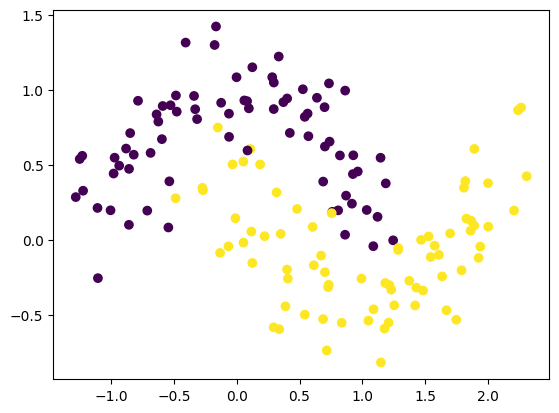

In [1]:
# Take a toy dataset for binary classification
# Сначала обучим без регулизации, а потом с min_samples_leaf=5

from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)
# Две вложенные луны
print(X_moons[5], X_moons.shape)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons) # Что за данные, все x1 = [:,0] все x2 = [:,1]
tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons)


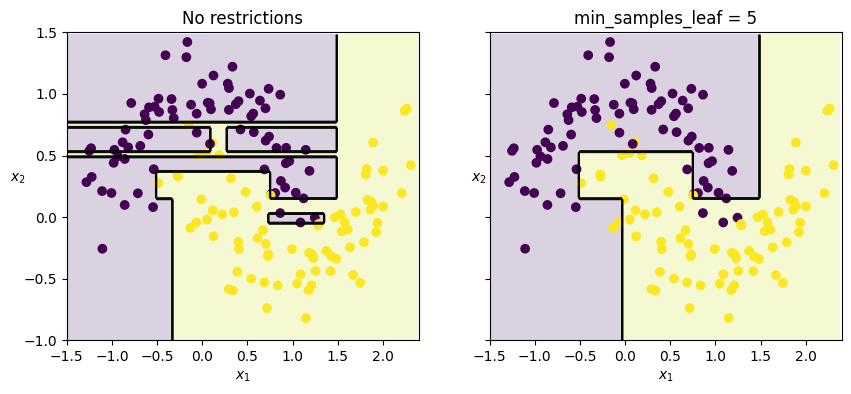

In [ ]:
def draw(clf, X, y, axes):
    x_min, x_max, y_min, y_max = axes
    # Разметить шахматную сетку x y по мин и максам с шагом 0.02 (дает больше клеток)
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    # Склеить их и предсказать получить классы [0,1]
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.2) # Желтый и фиолетовый фон; 0 жетлый, 1 фиолет
    plt.contour(xx, yy, Z, colors="k", linewidths=0.5) # Границы решений
    plt.scatter(X[:, 0], X[:, 1], c=y, marker="o") # точки
    plt.axis(axes)  # Задать диапазон осей
    plt.xlabel(r"$x_1$"); plt.ylabel(r"$x_2$", rotation=0)

# tree_clf1
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(ax1)
draw(tree_clf1, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5])
plt.title("No restrictions")

# tree_clf2
plt.sca(ax2)
draw(tree_clf2, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5])
plt.title("min_samples_leaf = 5")
plt.sca(ax2)

# Точки данные
# Цвет что предсказывает дерево в этой точке
# Черные линии границы решения

# Левое дерево (без ограничений):
# - тонкие полки и «карманы» — области, созданные ради 1–3 конкретных точек;
# - оно идеально попало в обучающие данные — и именно это плохо: такие полки выучены по шуму (переобучение).

# Правое (min_samples_leaf=5):
# - крупные, ровные области;
# - ни одна точка не может создать лист меньше 5 примеров → мелкие карманы невозможны;
# - несколько точек попало «не в свой» цвет — это нормальная плата за обобщение.


In [2]:
# Evaluating both trees on a test set

X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2, random_state=43)

print("tree_clf1:",tree_clf1.score(X_moons_test, y_moons_test))
print("tree_clf2", tree_clf2.score(X_moons_test,  y_moons_test))

tree_clf1: 0.898
tree_clf2 0.92


In [ ]:
# Regression

In [1]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import export_graphviz

rng = np.random.default_rng(seed=42)

# 200 чисел от 0 до 1, и - 0.5 будет от -0.5 до + 0.5 парабола симметрична вокруг 0
X_quad = rng.random((200, 1)) - 0.5
y_quad = X_quad ** 2 + 0.025 * rng.standard_normal((200, 1)) # идеальная парабола + грязь
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X_quad, y_quad)

export_graphviz(
    tree_reg,
    out_file="tree_regression.dot",
    feature_names=["x1"],
    rounded=True,
    filled=True,
)


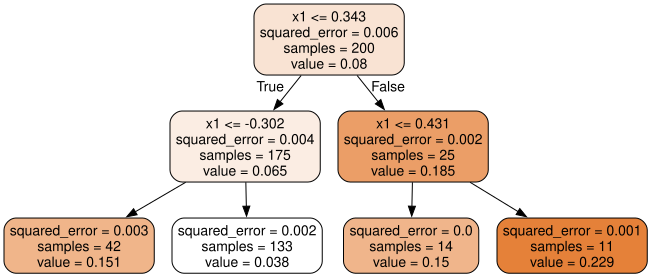

In [3]:
from graphviz import Source
Source.from_file("tree_regression.dot")

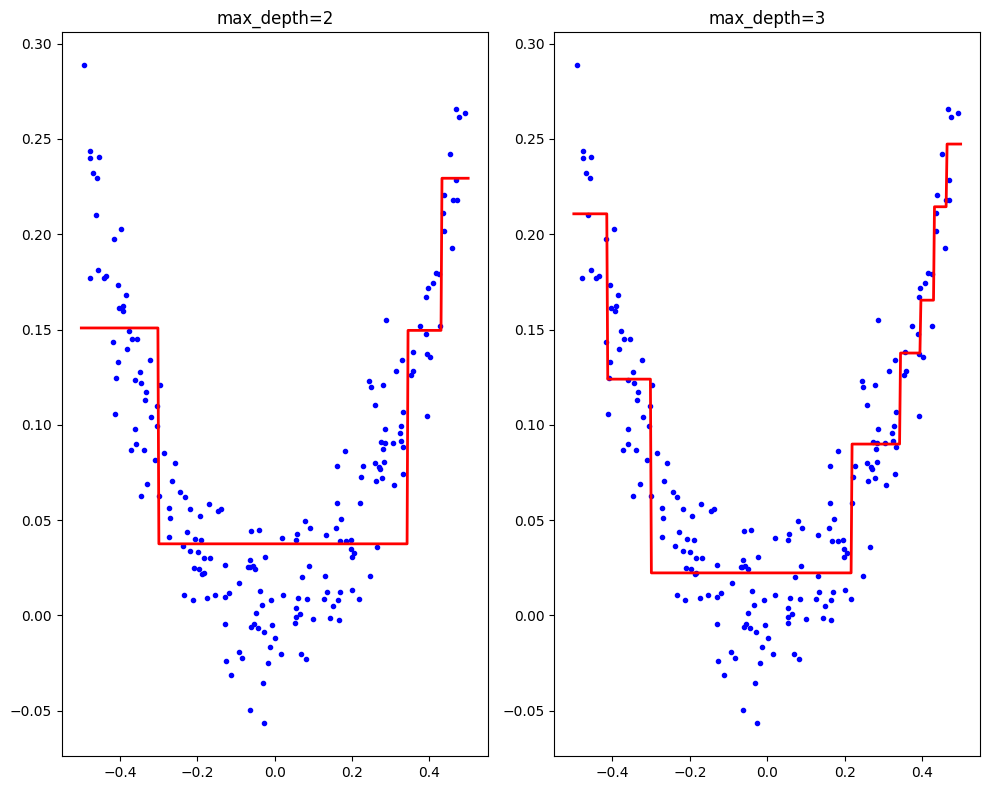

In [4]:
import matplotlib.pyplot as plt
t3 = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_quad, y_quad)
xs = np.linspace(-0.5, 0.5, 400).reshape(-1, 1)

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

axs[0].plot(X_quad, y_quad, '.b')
axs[0].set_title('max_depth=2')
axs[0].plot(xs, tree_reg.predict(xs), "r-", lw=2)

axs[1].plot(X_quad, y_quad, '.b')
axs[1].set_title('max_depth=3')
axs[1].plot(xs, t3.predict(xs), "r-", lw=2)

plt.tight_layout()
plt.show()

# Чем выше max_depth тем ближе к предсказанию (становится меньше MSE а р)

## Equation 5-4. CART cost function for regression

$$
J(k, t_k) = \frac{m_{left}}{m} MSE_{left} + \frac{m_{right}}{m} MSE_{right}
$$

where (объяснение)

$$
MSE_{node} = \frac{\sum_{i \in node}\left(\hat{y}_{node} - y^{(i)}\right)^2}{m_{node}}
$$

$$
\hat{y}_{node} = \frac{\sum_{i \in node} y^{(i)}}{m_{node}}
$$

ŷ_node   = Σ_{i ∈ node} y_i / m_node
Расшифровка:
m        = всего объектов в датасете
m_node   = число объектов в этом узле
ŷ_node   = среднее y объектов узла → это и есть предсказание узла
MSE_node = среднее квадратов отклонений y от ŷ_node, только по объектам этого узла
J        = взвешенное MSE двух детей; CART перебирает пороги и выбирает минимальный J

Text(0, 0.5, 'y')

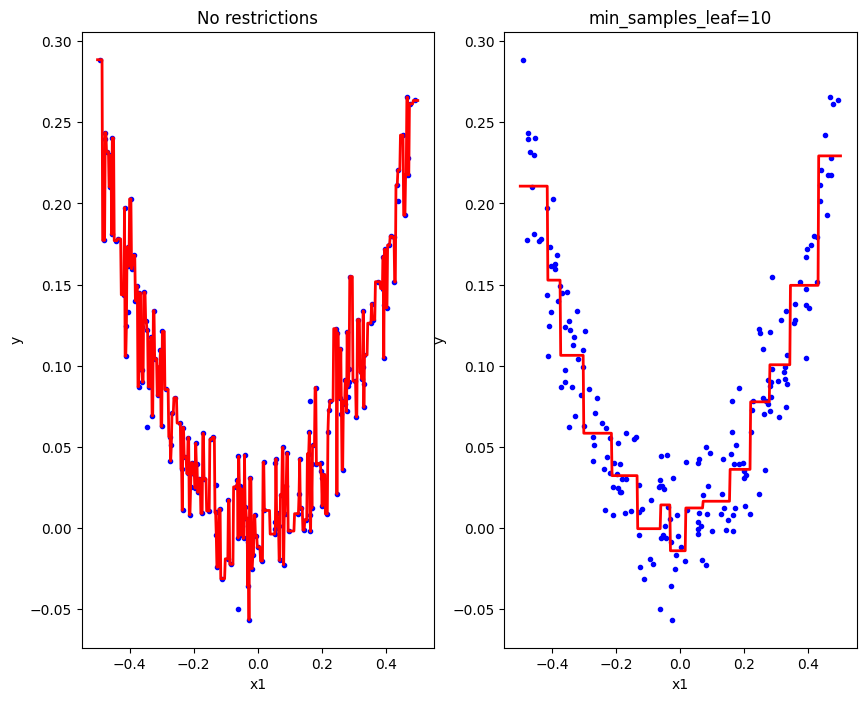

In [14]:

# Как и в classification tasks, decision trees склонны к переобучению когда работают с regression tasks.
# Без каких либо параметров будет сильное переобучение (картинка слева)
# Но если поставить хотя бы min_samples_leaf станет уже лучше

x1 = np.linspace(-0.5, 0.5, 500).reshape(-1, 1) # 500 предсказаний на сетке
tree_reg_no_restrict = DecisionTreeRegressor(random_state=42).fit(X_quad, y_quad)
tree_reg_min_smp_leaf = DecisionTreeRegressor(random_state=42, min_samples_leaf=10).fit(X_quad, y_quad)


fig, axs = plt.subplots(1, 2, figsize=(10, 8))

axs[0].plot(X_quad, y_quad, '.b')
axs[0].set_title('No restrictions')
axs[0].plot(x1, tree_reg_no_restrict.predict(x1), "r-", lw=2)
axs[0].set_xlabel("x1")
axs[0].set_ylabel("y")

axs[1].plot(X_quad, y_quad, '.b')
axs[1].set_title('min_samples_leaf=10')
axs[1].plot(x1, tree_reg_min_smp_leaf.predict(x1), "r-", lw=2)
axs[1].set_xlabel("x1")
axs[1].set_ylabel("y")

In [23]:
# Про MSE чуть подробнее и выборе гиперпараметров
# Идея: depth выбираем не по train (там всегда побеждает самая глубокая модель,
# потому что она запомнила точки), а по данным, которые модель НЕ видела.

from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(X_quad, y_quad, test_size=0.3, random_state=43)
# X_tr  — на этом учим
# X_val — на этом мерим; эти y модель никогда не видела, поэтому цифра честная

min_mse = float("inf")     # стартовое «худшее возможное значение», иначе сравнение может сломаться
best_mse_d = None

for d in range(1, 21):
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_tr, y_tr)
    err = y_val.reshape(-1) - t.predict(X_val).reshape(-1)
    #     реальное y − предсказание = ошибка каждой точки, всего 60 чисел
    sq = err ** 2
    #     квадрат каждой ошибки: убирает минус, усиливает большие ошибки
    mse = round(sq.mean(), 6)
    #              ^          ^
    #              |          └ 6 знаков (красивый вывод)
    #              └ среднее по 60 точкам

    if min_mse > mse:      # берём МИНИМУМ на validation, а не «самую глубокую модель»
        min_mse = mse
        best_mse_d = d
    print(d, mse)

print("best depth:", best_mse_d, "min mse:", min_mse)

# Что это значит словами:
# d=4 — глубина, где усреднение в leaf'ах ещё достаточно большое, чтобы ловить
# закономерность, но зоны уже достаточно мелкие, чтобы она не размывалась.
# После d=4 зоны становятся слишком маленькими (иногда 1 точка) → модель
# начинает выдавать шум конкретной точки → MSE на validation растёт.

# Важно: здесь нет test-набора. Если потом хочешь сказать «модель работает
# на новых данных с MSE ≈ …», нужен третий набор, который вообще не участвовал
# в этом цикле. Здесь validation уже потрачен на выбор из 20 вариантов,
# поэтому его цифра слегка оптимистична.

1 0.003389
2 0.001333
3 0.000848
4 0.000731
5 0.000826
6 0.000947
7 0.001
8 0.001022
9 0.001056
10 0.001088
11 0.001139
12 0.001223
13 0.001225
14 0.001221
15 0.001221
16 0.001221
17 0.001221
18 0.001221
19 0.001221
20 0.001221
best depth: 4 min mse: 0.000731
